In [2]:
from google.colab import files
uploaded = files.upload()

Saving Dataset.csv to Dataset.csv


In [3]:
import pandas as pd

df = pd.read_csv("Dataset.csv")

print("Dataset Shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

print("\nContent Type Distribution:")
print(df["type"].value_counts())

Dataset Shape: (8790, 10)

Columns:
['show_id', 'type', 'title', 'director', 'country', 'date_added', 'release_year', 'rating', 'duration', 'listed_in']

Content Type Distribution:
type
Movie      6126
TV Show    2664
Name: count, dtype: int64


In [4]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

features = ["release_year", "director", "country", "rating", "listed_in"]
target = "type"

X = df[features].copy()
y = df[target].copy()

X["release_year"] = X["release_year"].fillna(X["release_year"].median())

for col in ["director", "country", "rating", "listed_in"]:
    X[col] = X[col].fillna("Unknown")

print("Features prepared successfully!")
print("Total records:", len(X))
print("Missing values remaining:", X.isnull().sum().sum())

Features prepared successfully!
Total records: 8790
Missing values remaining: 0


In [5]:
numeric_features = ["release_year"]
categorical_features = ["director", "country", "rating", "listed_in"]

preprocessor = ColumnTransformer(
    transformers=[
        ("num", "passthrough", numeric_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
    ]
)

model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        class_weight="balanced"
    ))
])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("Model training completed successfully!")

Model training completed successfully!


In [6]:
accuracy = accuracy_score(y_test, y_pred)

print(f"Model Accuracy: {accuracy * 100:.2f}%")
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

Model Accuracy: 98.29%

Classification Report:
              precision    recall  f1-score   support

       Movie       0.98      0.99      0.99      1225
     TV Show       0.98      0.96      0.97       533

    accuracy                           0.98      1758
   macro avg       0.98      0.98      0.98      1758
weighted avg       0.98      0.98      0.98      1758


Confusion Matrix:
[[1216    9]
 [  21  512]]


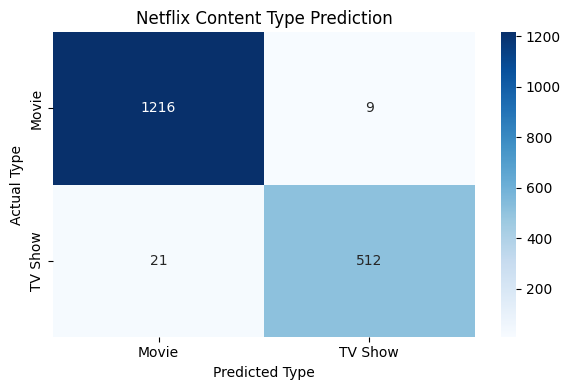

In [7]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 4))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=model.classes_,
    yticklabels=model.classes_
)

plt.xlabel("Predicted Type")
plt.ylabel("Actual Type")
plt.title("Netflix Content Type Prediction")
plt.tight_layout()
plt.show()

In [8]:
new_content = pd.DataFrame([{
    "release_year": 2022,
    "director": "Unknown",
    "country": "United States",
    "rating": "TV-MA",
    "listed_in": "Dramas, International Movies"
}])

prediction = model.predict(new_content)

print("Predicted Content Type:", prediction[0])

Predicted Content Type: Movie


In [9]:
import joblib

joblib.dump(model, "Netflix_Content_Type_Model.pkl")

print("Model saved successfully!")

Model saved successfully!


In [10]:
from google.colab import files

files.download("Netflix_Content_Type_Model.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>